# Visualização - Dados Mensais XAVIER (Rio Grande do Sul)

Notebook para explorar dados de precipitação mensal acumulada.

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

## 1. Carregar Dados Mensais Combinados

In [2]:
# Carregar arquivo combinado (1961-2019)
file = "../data/processed/xavier_monthly/pr_monthly_1961_2019_RS_combined.nc"
ds = xr.open_dataset(file)

print(f"📅 Período: {ds.time.min().dt.year.item()}-{ds.time.max().dt.year.item()}")
print(f"📊 Meses: {len(ds.time)}")
print(f"🗺️  Grade: {len(ds.latitude)} lat × {len(ds.longitude)} lon")
print(f"📏 Unidade: {ds.pr.attrs.get('units', 'N/A')}")

ds

📅 Período: 1961-2024
📊 Meses: 768
🗺️  Grade: 89 lat × 130 lon
📏 Unidade: mm/month


<xarray.Dataset>
Dimensions:            (latitude: 89, longitude: 130, time: 768)
Coordinates:
  * latitude           (latitude) float32 -33.85 -33.75 -33.65 ... -25.15 -25.05
  * longitude          (longitude) float32 -59.95 -59.85 ... -47.15 -47.05
  * time               (time) datetime64[ns] 1961-01-31 ... 2024-12-31
    step               timedelta64[ns] ...
    surface            float64 ...
Data variables:
    pr                 (time, latitude, longitude) float64 ...
    ETo                (time, latitude, longitude) float64 ...
    RH                 (time, latitude, longitude) float64 ...
    Rs                 (time, latitude, longitude) float64 ...
    Tmax               (time, latitude, longitude) float64 ...
    Tmin               (time, latitude, longitude) float64 ...
    u2                 (time, latitude, longitude) float64 ...
    interpolated_mask  (time, latitude, longitude) float64 ...
Attributes:
    title:                Brazilian Daily Weather Gridded Data (1961-2020)
    institution:          Federal University of Espirito Santo; University of...
    institution_id:       UFES; UTEXAS
    history:              Created Mon Jun 12 15:02:05 2023
    temporal_resolution:  24-hourly
    contact:              alexandre.xavier@ufes.br; careyking@energy.utexas.e...
    main_code:            gerando_ncfiles_pr_8bits.py
    update_information:   https://sites.google.com/site/alexandrecandidoxavie...
    main_paper:           Xavier, A.C., Scanlon, B.R., King, C.W. and Alves, ...
    Interpolate_method:   ADW, power: 5; n_neighbor: 5; variation_with_height...
    source:               Processed from pr_19610101_19801231_BR-DWGD_UFES_UT...
    processing:           Daily to monthly accumulation

## 2. Série Temporal - Média Espacial

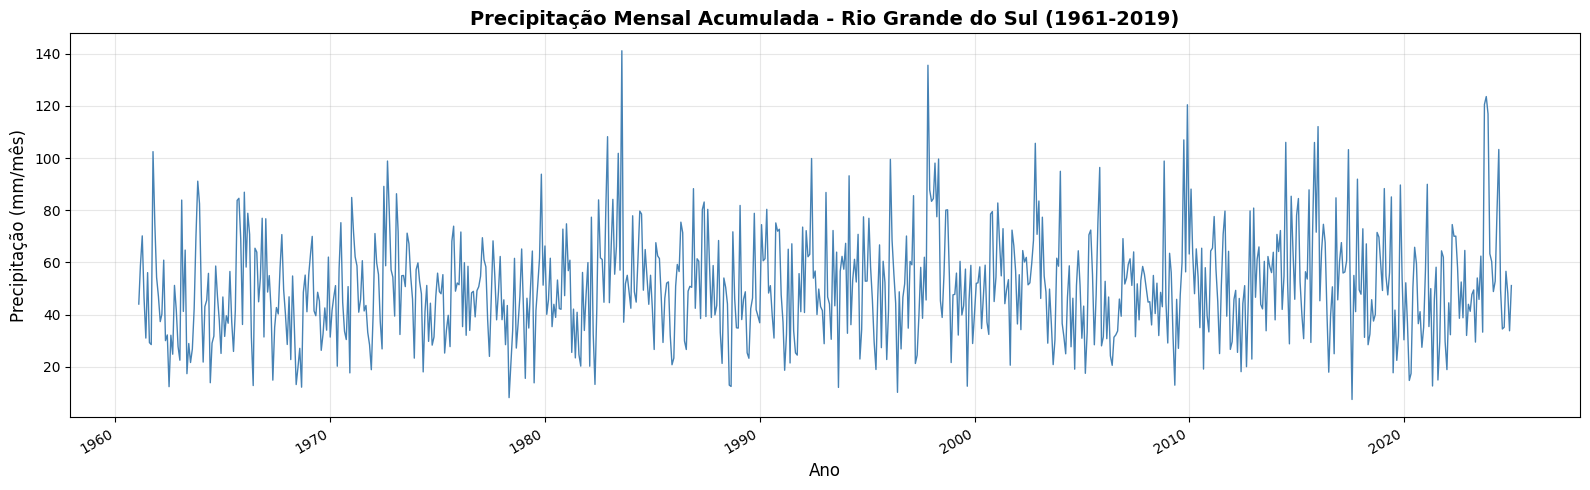

In [3]:
# Média espacial mensal
precip_ts = ds.pr.mean(['latitude', 'longitude'])

fig, ax = plt.subplots(figsize=(16, 5))
precip_ts.plot(ax=ax, color='steelblue', linewidth=1)
ax.set_title('Precipitação Mensal Acumulada - Rio Grande do Sul (1961-2019)', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('Precipitação (mm/mês)', fontsize=12)
ax.set_xlabel('Ano', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Ciclo Anual Médio

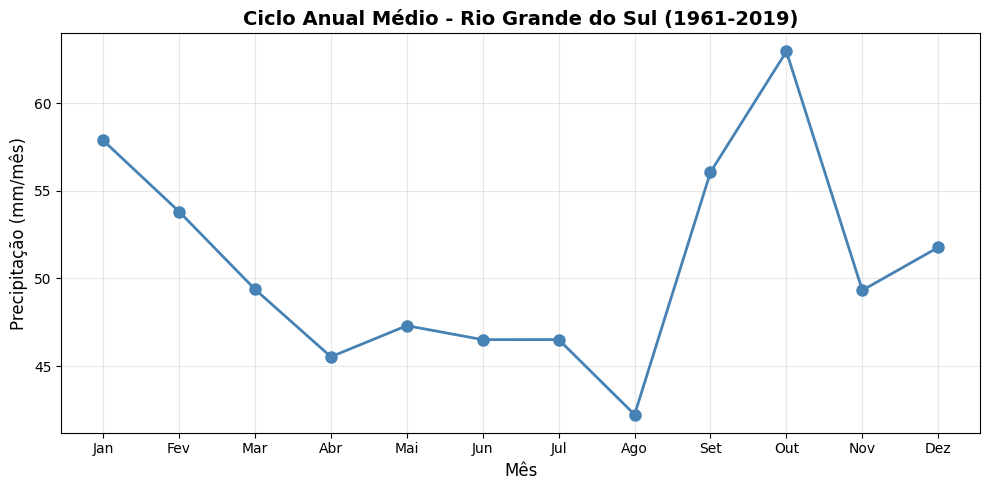


Precipitação média por mês (mm):
   1: 57.9
   2: 53.8
   3: 49.4
   4: 45.5
   5: 47.3
   6: 46.5
   7: 46.5
   8: 42.2
   9: 56.1
  10: 62.9
  11: 49.3
  12: 51.8


In [4]:
# Climatologia mensal
monthly_clim = ds.pr.groupby('time.month').mean(['time', 'latitude', 'longitude'])

fig, ax = plt.subplots(figsize=(10, 5))
monthly_clim.plot(ax=ax, marker='o', linewidth=2, markersize=8, color='steelblue')
ax.set_title('Ciclo Anual Médio - Rio Grande do Sul (1961-2019)', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('Precipitação (mm/mês)', fontsize=12)
ax.set_xlabel('Mês', fontsize=12)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 
                     'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nPrecipitação média por mês (mm):")
for month, value in enumerate(monthly_clim.values, 1):
    print(f"  {month:2d}: {value:.1f}")

## 4. Mapas de Precipitação Média Mensal

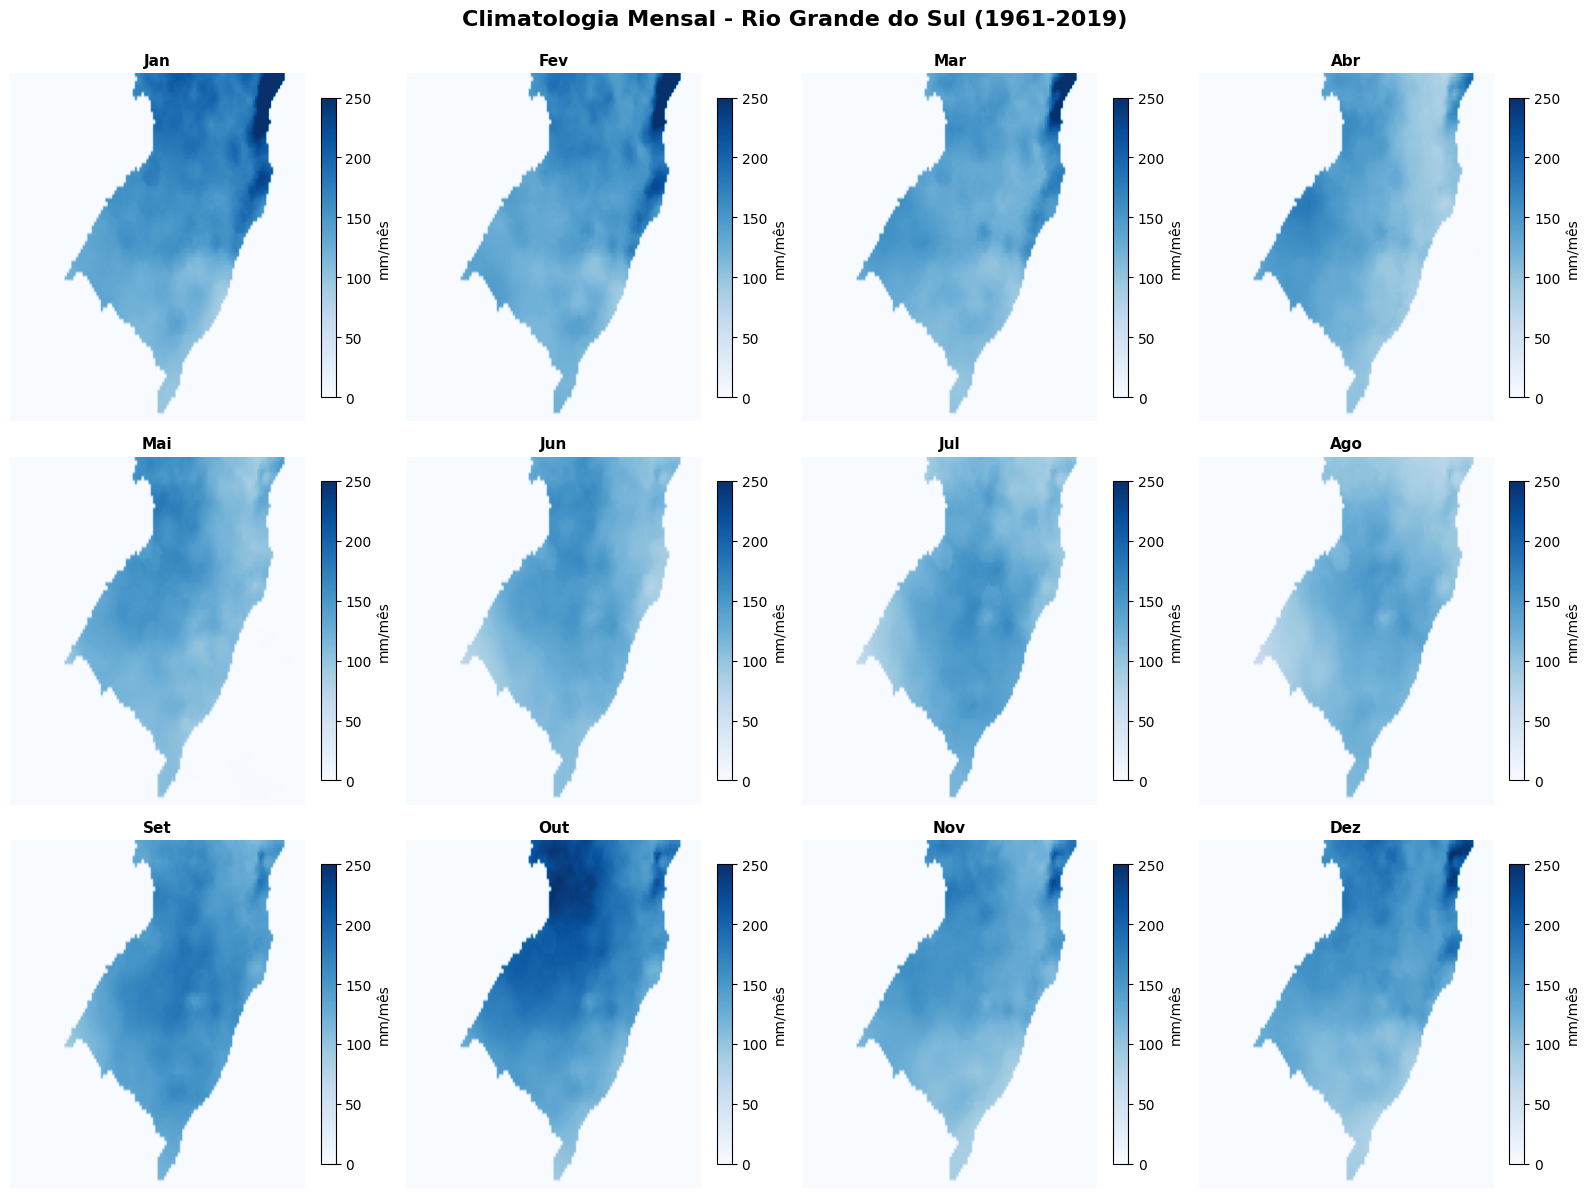

In [5]:
# Média por mês do ano
monthly_maps = ds.pr.groupby('time.month').mean('time')

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

months = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 
          'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

for i, (month_num, month_name) in enumerate(zip(range(1, 13), months)):
    ax = axes[i]
    data = monthly_maps.sel(month=month_num)
    
    im = ax.imshow(data, cmap='Blues', vmin=0, vmax=250, 
                   aspect='auto', origin='lower')
    ax.set_title(month_name, fontsize=11, fontweight='bold')
    ax.axis('off')
    
    plt.colorbar(im, ax=ax, fraction=0.046, label='mm/mês')

plt.suptitle('Climatologia Mensal - Rio Grande do Sul (1961-2019)', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 5. Anomalias Mensais

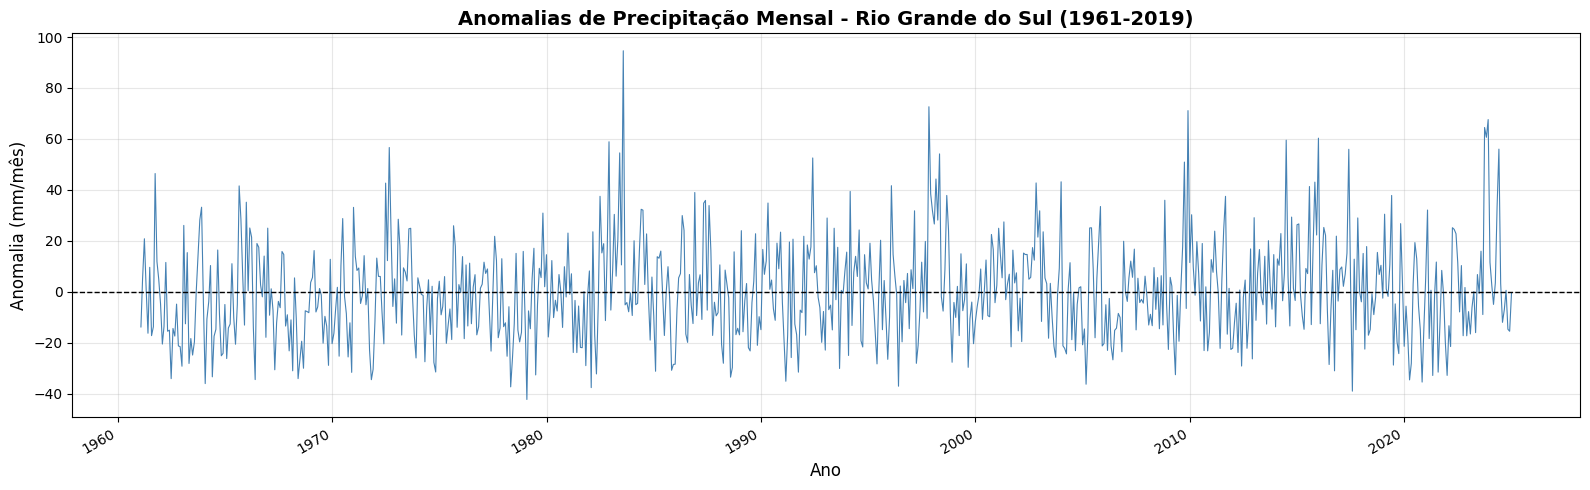

In [6]:
# Calcular anomalias
climatology = ds.pr.groupby('time.month').mean('time')
anomalies = ds.pr.groupby('time.month') - climatology

# Série temporal de anomalias (média espacial)
anom_ts = anomalies.mean(['latitude', 'longitude'])

fig, ax = plt.subplots(figsize=(16, 5))
anom_ts.plot(ax=ax, color='steelblue', linewidth=0.8)
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set_title('Anomalias de Precipitação Mensal - Rio Grande do Sul (1961-2019)', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('Anomalia (mm/mês)', fontsize=12)
ax.set_xlabel('Ano', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Estatísticas por Década

Precipitação média por década (mm/mês):
  1960s: 45.6
  1970s: 48.5
  1980s: 51.3
  1990s: 53.0
  2000s: 51.2
  2010s: 54.3
  2020s: 51.1


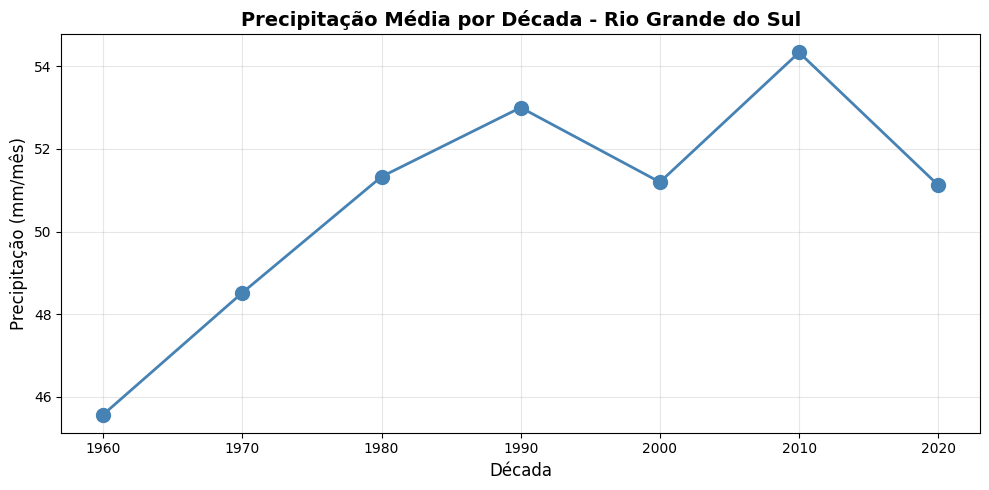

In [7]:
# Agrupar por década
decades = ds.pr.groupby((ds.time.dt.year // 10) * 10).mean(['time', 'latitude', 'longitude'])

print("Precipitação média por década (mm/mês):")
print("="*40)
for decade, value in zip(decades.year.values, decades.values):
    print(f"  {decade}s: {value:.1f}")

# Plotar
fig, ax = plt.subplots(figsize=(10, 5))
decades.plot(ax=ax, marker='o', markersize=10, linewidth=2, color='steelblue')
ax.set_title('Precipitação Média por Década - Rio Grande do Sul', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('Precipitação (mm/mês)', fontsize=12)
ax.set_xlabel('Década', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Mapa de Variabilidade Espacial

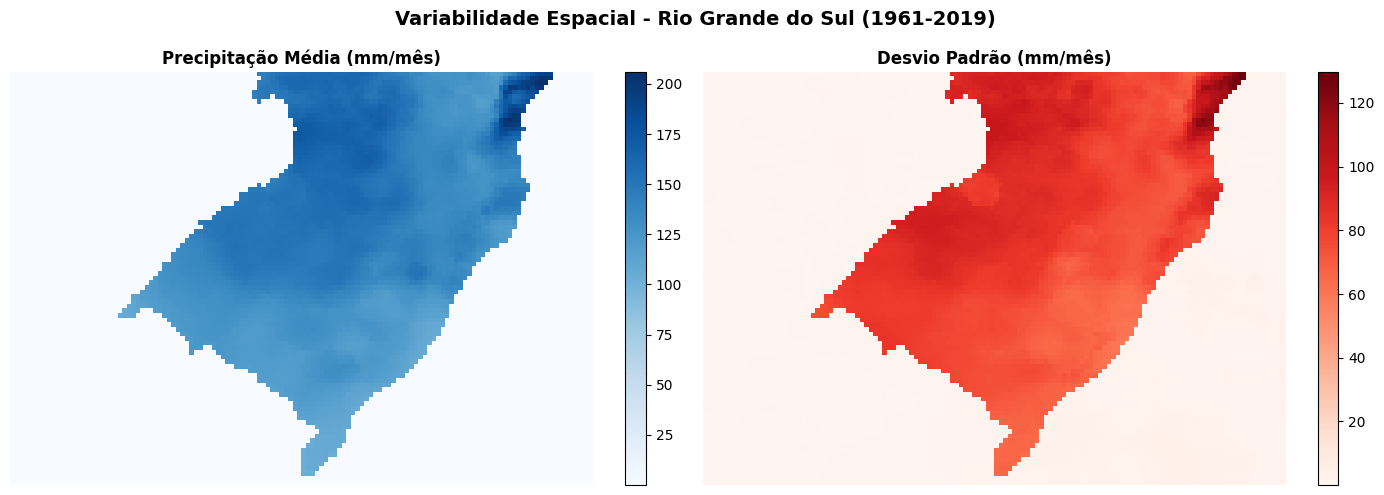

In [8]:
# Desvio padrão temporal
precip_std = ds.pr.std('time')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Média
im1 = ax1.imshow(ds.pr.mean('time'), cmap='Blues', aspect='auto', origin='lower')
ax1.set_title('Precipitação Média (mm/mês)', fontsize=12, fontweight='bold')
ax1.axis('off')
plt.colorbar(im1, ax=ax1, fraction=0.046)

# Desvio padrão
im2 = ax2.imshow(precip_std, cmap='Reds', aspect='auto', origin='lower')
ax2.set_title('Desvio Padrão (mm/mês)', fontsize=12, fontweight='bold')
ax2.axis('off')
plt.colorbar(im2, ax=ax2, fraction=0.046)

plt.suptitle('Variabilidade Espacial - Rio Grande do Sul (1961-2019)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Exportar Dados para Análise

In [9]:
# Exportar série temporal média para CSV
output_dir = Path("../data/processed/xavier_monthly")

# Criar DataFrame
df = pd.DataFrame({
    'date': precip_ts.time.values,
    'precipitation_mm': precip_ts.values,
    'anomaly_mm': anom_ts.values
})

df.to_csv(output_dir / 'xavier_monthly_timeseries_RS.csv', index=False)
print(f"✅ Série temporal salva: {output_dir / 'xavier_monthly_timeseries_RS.csv'}")

# Mostrar primeiras linhas
df.head()

✅ Série temporal salva: ../data/processed/xavier_monthly/xavier_monthly_timeseries_RS.csv


,date,precipitation_mm,anomaly_mm
0,1961-01-31,44.059527,-13.814397
1,1961-02-28,58.922903,5.107311
2,1961-03-31,70.190427,20.807142
3,1961-04-30,46.674922,1.139783
4,1961-05-31,31.027767,-16.282255
